# Atividade 3 — Filtragem de Imagens e Análise de Ruído

**Unidade 2 | Capítulo 1 | Tarefa 3**  
**Aluno:** Luiz Felipe Souza da Silva  
**Professor:** Rafael Carmo

## Objetivo

Nesta atividade, adiciono ruído gaussiano e sal e pimenta a uma imagem de cada classe.
Depois aplico filtros gaussianos 3×3 e 7×7 no domínio da frequência e um filtro passa-alta.
O objetivo é comparar a redução do ruído com a perda ou o realce de detalhes importantes.

As imagens originais são usadas como referência para calcular o PSNR. Isso não significa
que as fotografias sejam completamente livres de ruído; apenas permite medir a degradação
artificial adicionada neste experimento.

## Preparação

Execute as células em ordem. Se necessário, instale as bibliotecas em uma célula separada:
`%pip install numpy pandas matplotlib pillow opencv-python`.

In [1]:
from pathlib import Path
import json
import platform
import subprocess
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
import PIL
from IPython.display import display, Markdown

try:
    import google.colab
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'dataset/originais').is_dir()), None)
if RAIZ is None and EM_COLAB:
    RAIZ = Path('/content/VC_iREDE')
    if not RAIZ.exists():
        subprocess.run(['git','clone','https://github.com/luix-felipe/VC_iREDE.git',str(RAIZ)],check=True)
if RAIZ is None or not (RAIZ/'dataset/originais').is_dir():
    raise FileNotFoundError('Disponibilize o projeto com dataset/originais.')

DERIVADAS = RAIZ/'dataset/derivadas/atividade_3'
TABELAS = RAIZ/'tabelas/atividade_3'
FIGURAS = DERIVADAS/'figuras'
for pasta in [DERIVADAS,TABELAS,FIGURAS]:
    pasta.mkdir(parents=True,exist_ok=True)

cv2.setNumThreads(2)
plt.rcParams.update({'figure.dpi':100,'font.size':10,'axes.titlesize':10})
versoes = {'Python':platform.python_version(),'NumPy':np.__version__,
           'pandas':pd.__version__,'OpenCV':cv2.__version__,
           'Matplotlib':matplotlib.__version__,'Pillow':PIL.__version__}
(TABELAS/'ambiente.json').write_text(json.dumps(versoes,indent=2),encoding='utf-8')

def mostrar_tabela(df, colunas):
    display(df[list(colunas)].rename(columns=colunas).style.hide(axis='index')
            .format(precision=2,na_rep='—'))

def finalizar_figura(fig,nome):
    fig.tight_layout()
    fig.savefig(FIGURAS/f'{nome}.png',dpi=120,bbox_inches='tight')
    plt.show()
    plt.close(fig)

def recortar(imagem,caixa):
    x0,y0,x1,y1=caixa
    return imagem[y0:y1,x0:x1]

def salvar_imagem(imagem,caminho):
    caminho.parent.mkdir(parents=True,exist_ok=True)
    saida=np.rint(np.clip(imagem,0,1)*255).astype(np.uint8)
    Image.fromarray(saida).save(caminho)

def calcular_psnr(referencia,resultado):
    mse=float(np.mean((resultado.astype(np.float64)-referencia)**2))
    return float('inf') if mse==0 else float(10*np.log10(1/mse))

## 1. Seleção das imagens

Foram escolhidas `fpga_04.jpg` e `contrabaixo_02.jpg`, uma imagem de cada classe.
A primeira contém componentes, inscrições e terminais; a segunda contém cordas,
captadores e regiões claras e escuras. Esses elementos ajudam a observar a perda de
detalhes causada pelos ruídos e filtros.

Os retângulos laranja mostram os recortes usados nas comparações. Os cálculos são feitos
nas imagens inteiras, sem redução de resolução.

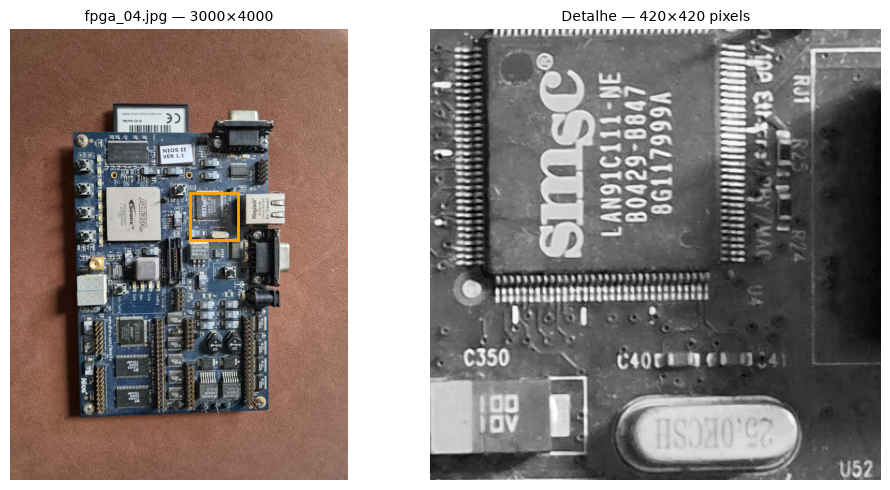

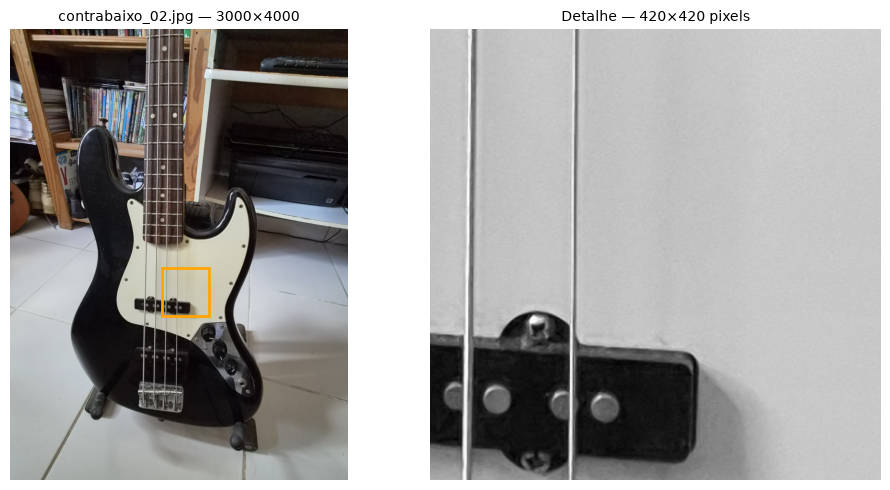

Imagem,Classe,Formato,Largura (px),Altura (px)
fpga_04.jpg,fpga,JPEG,3000,4000
contrabaixo_02.jpg,contrabaixo,JPEG,3000,4000


In [2]:
SELECAO = [
    {'classe':'fpga','arquivo':'fpga_04.jpg','detalhe':(1600,1450,2020,1870),'semente':301},
    {'classe':'contrabaixo','arquivo':'contrabaixo_02.jpg','detalhe':(1350,2120,1770,2540),'semente':302}
]
IMAGENS={}
registros=[]
for item in SELECAO:
    caminho=RAIZ/'dataset/originais'/item['classe']/item['arquivo']
    with Image.open(caminho) as foto:
        formato=foto.format
        rgb=np.array(ImageOps.exif_transpose(foto).convert('RGB'))
    cinza=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY).astype(np.float32)/255
    altura,largura=cinza.shape
    IMAGENS[item['classe']]=cinza
    registros.append({'imagem':item['arquivo'],'classe':item['classe'],
                      'formato':formato,'largura_px':largura,'altura_px':altura})
    salvar_imagem(cinza,DERIVADAS/'originais_cinza'/item['classe']/'referencia.png')

    x0,y0,x1,y1=item['detalhe']
    fig,eixos=plt.subplots(1,2,figsize=(10,5))
    mini=cv2.resize(rgb,(largura//4,altura//4),interpolation=cv2.INTER_AREA)
    eixos[0].imshow(mini,extent=(0,largura,altura,0))
    eixos[0].add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor='orange',linewidth=2))
    eixos[0].set_title(f"{item['arquivo']} — {largura}×{altura}")
    eixos[1].imshow(recortar(cinza,item['detalhe']),cmap='gray',vmin=0,vmax=1)
    eixos[1].set_title('Detalhe — 420×420 pixels')
    for eixo in eixos:eixo.axis('off')
    finalizar_figura(fig,f"selecao_{item['classe']}")

selecao=pd.DataFrame(registros)
selecao.to_csv(TABELAS/'selecao_imagens.csv',index=False)
mostrar_tabela(selecao,{'imagem':'Imagem','classe':'Classe','formato':'Formato',
                       'largura_px':'Largura (px)','altura_px':'Altura (px)'})

## 2. Inserção de ruído

O ruído gaussiano foi criado com média 0 e desvio-padrão 0,08 na escala de 0 a 1.
Ele produz pequenas variações espalhadas pela imagem. A distribuição espacial é semelhante
em toda a matriz, mas os valores sorteados seguem uma distribuição normal, não uniforme.

No ruído sal e pimenta, 5% das posições são escolhidas sem repetição: metade recebe 0
e metade recebe 1. Ele aparece como pontos claros e escuros isolados. Esse tipo de ruído
pode representar falhas de pixels, leitura ou transmissão. As sementes fixas permitem
reproduzir exatamente o mesmo experimento.

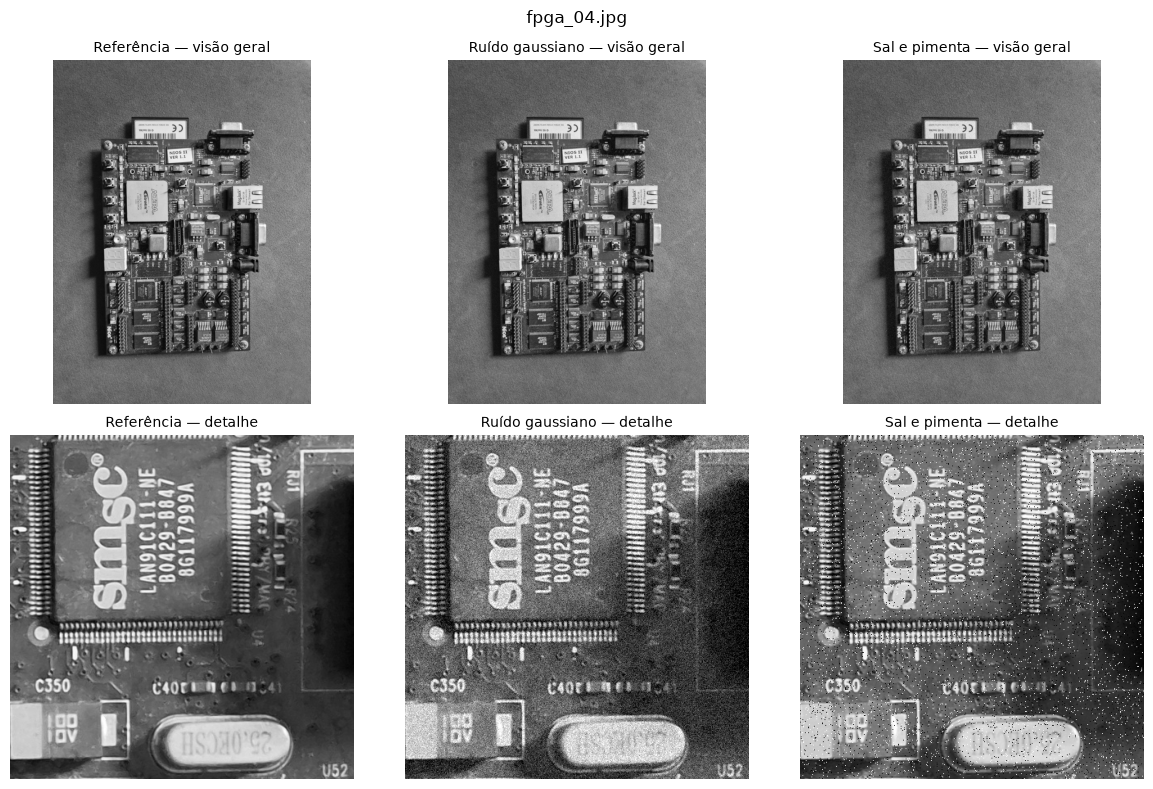

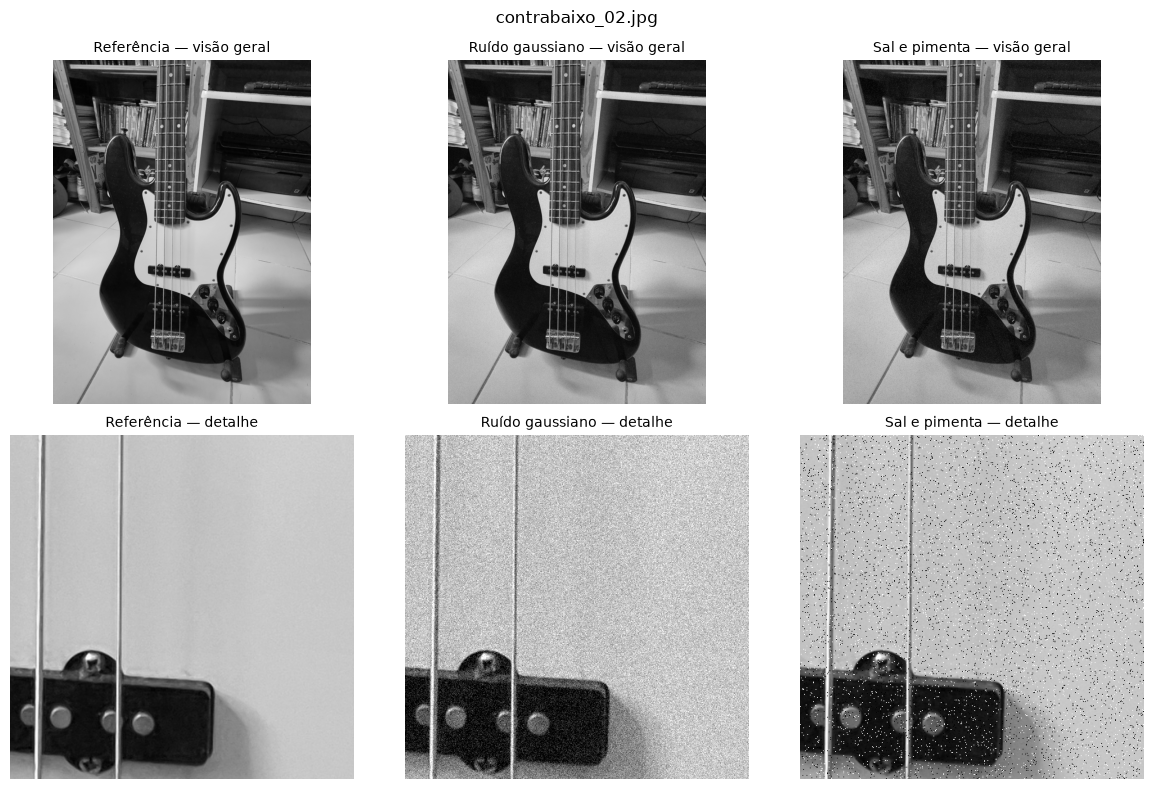

Classe,Ruído,Parâmetro,Pixels modificados (%),PSNR (dB)
fpga,gaussiano,"média 0; σ 0,08",99.99,22.07
fpga,sal_pimenta,5% das posições,5.00,18.35
contrabaixo,gaussiano,"média 0; σ 0,08",99.99,22.32
contrabaixo,sal_pimenta,5% das posições,5.00,17.73


In [3]:
MEDIA_RUIDO=0.0
DESVIO_RUIDO=0.08
FRACAO_SP=0.05

def adicionar_gaussiano(imagem,semente):
    gerador=np.random.default_rng(semente)
    ruido=gerador.normal(MEDIA_RUIDO,DESVIO_RUIDO,imagem.shape)
    return np.clip(imagem+ruido,0,1).astype(np.float32)

def adicionar_sal_pimenta(imagem,semente):
    gerador=np.random.default_rng(semente)
    resultado=imagem.copy()
    quantidade=round(FRACAO_SP*imagem.size)
    posicoes=gerador.choice(imagem.size,size=quantidade,replace=False)
    resultado.flat[posicoes[:quantidade//2]]=0
    resultado.flat[posicoes[quantidade//2:]]=1
    return resultado

RUIDOS={}
linhas=[]
for item in SELECAO:
    classe=item['classe']
    referencia=IMAGENS[classe]
    gaussiano=adicionar_gaussiano(referencia,item['semente'])
    sal_pimenta=adicionar_sal_pimenta(referencia,item['semente']+1000)
    RUIDOS[classe]={'gaussiano':gaussiano,'sal_pimenta':sal_pimenta}
    for nome,imagem in RUIDOS[classe].items():
        linhas.append({'imagem':item['arquivo'],'classe':classe,'ruido':nome,
            'parametro':'média 0; σ 0,08' if nome=='gaussiano' else '5% das posições',
            'pixels_alterados_percentual':100*np.mean(imagem!=referencia),
            'psnr_db':calcular_psnr(referencia,imagem)})
        salvar_imagem(imagem,DERIVADAS/'ruido'/classe/f'{nome}.png')

    fig,eixos=plt.subplots(2,3,figsize=(12,8))
    imagens=[referencia,gaussiano,sal_pimenta]
    titulos=['Referência','Ruído gaussiano','Sal e pimenta']
    for coluna,(imagem,titulo) in enumerate(zip(imagens,titulos)):
        eixos[0,coluna].imshow(cv2.resize(imagem,(imagem.shape[1]//4,imagem.shape[0]//4),
                                          interpolation=cv2.INTER_AREA),cmap='gray',vmin=0,vmax=1)
        eixos[1,coluna].imshow(recortar(imagem,item['detalhe']),cmap='gray',vmin=0,vmax=1)
        eixos[0,coluna].set_title(titulo+' — visão geral')
        eixos[1,coluna].set_title(titulo+' — detalhe')
    for eixo in eixos.flat:eixo.axis('off')
    fig.suptitle(item['arquivo'])
    finalizar_figura(fig,f'ruidos_{classe}')

ruidos=pd.DataFrame(linhas)
ruidos.to_csv(TABELAS/'ruidos.csv',index=False)
mostrar_tabela(ruidos,{'classe':'Classe','ruido':'Ruído','parametro':'Parâmetro',
                      'pixels_alterados_percentual':'Pixels modificados (%)','psnr_db':'PSNR (dB)'})

### Efeito dos ruídos

O gaussiano forma uma granulação distribuída e dificulta a separação de regiões com
intensidades próximas. O sal e pimenta cria impulsos que podem ser confundidos com
pequenos componentes ou bordas. Ambos podem prejudicar limiarização, segmentação,
descritores de textura e detecção de contornos.

Visualmente, o sal e pimenta se diferencia pelos pontos extremos, enquanto o gaussiano
altera quase todos os pixels em menor intensidade. Com os parâmetros usados, o sal e
pimenta apresentou o menor PSNR nas duas classes e, portanto, a maior degradação numérica.

## 3. Filtro passa-baixa gaussiano no domínio da frequência

Foram testados kernels 3×3 com σ=0,8 e 7×7 com σ=1,4. Cada kernel é transformado por DFT
e multiplicado pelo espectro da imagem. Depois, a transformada inversa retorna ao domínio
espacial. A margem refletida evita que lados opostos da fotografia sejam tratados como
vizinhos pela convolução circular.

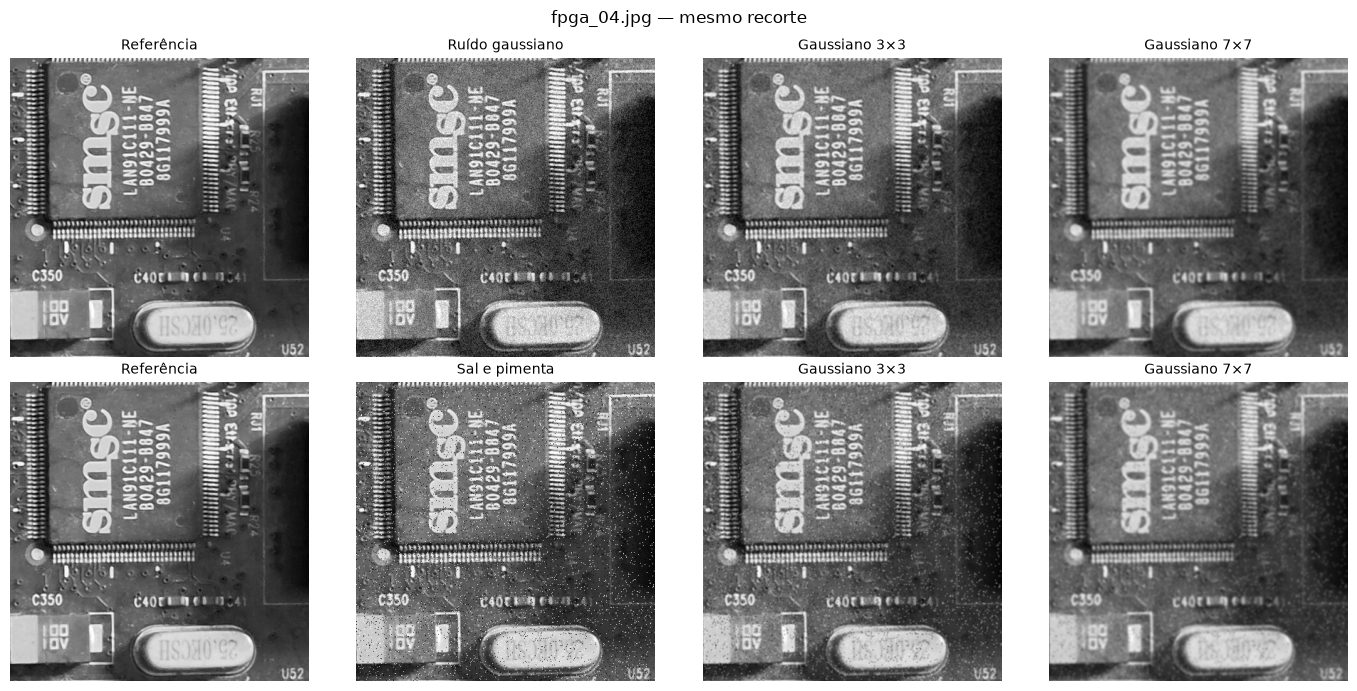

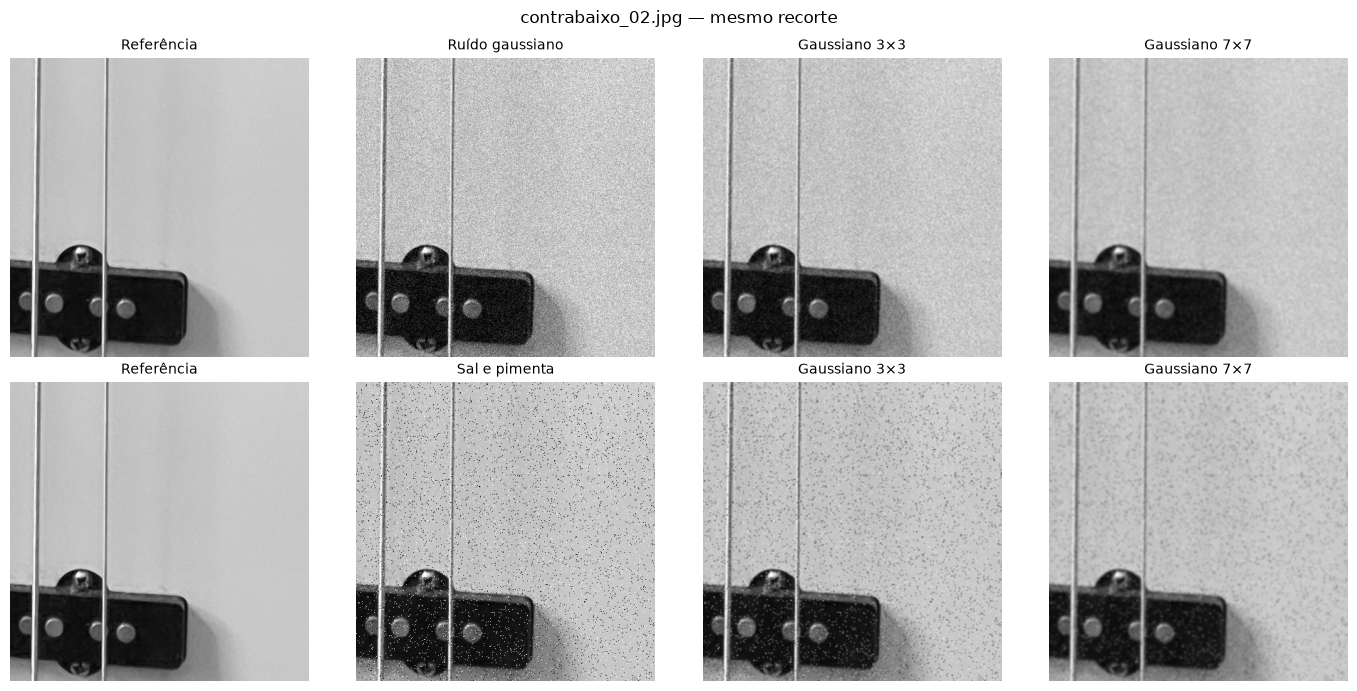

**FPGA**

Ruído,Kernel,PSNR antes (dB),PSNR depois (dB),Ganho (dB)
gaussiano,3x3,22.07,28.92,6.85
gaussiano,7x7,22.07,27.67,5.61
sal_pimenta,3x3,18.35,25.73,7.37
sal_pimenta,7x7,18.35,26.47,8.12


**CONTRABAIXO**

Ruído,Kernel,PSNR antes (dB),PSNR depois (dB),Ganho (dB)
gaussiano,3x3,22.32,30.11,7.79
gaussiano,7x7,22.32,32.29,9.97
sal_pimenta,3x3,17.73,25.53,7.81
sal_pimenta,7x7,17.73,28.98,11.25


In [4]:
def kernel_gaussiano(tamanho,sigma):
    eixo=np.arange(tamanho,dtype=np.float32)-tamanho//2
    vetor=np.exp(-(eixo**2)/(2*sigma**2))
    vetor/=vetor.sum()
    return np.outer(vetor,vetor).astype(np.float32)

KERNELS={'3x3':kernel_gaussiano(3,0.8),'7x7':kernel_gaussiano(7,1.4)}

def filtrar_frequencia(imagem,kernel):
    kh,kw=kernel.shape
    ry,rx=kh//2,kw//2
    borda=cv2.copyMakeBorder(imagem.astype(np.float32),ry,ry,rx,rx,cv2.BORDER_REFLECT_101)
    altura,largura=borda.shape
    forma=(cv2.getOptimalDFTSize(altura),cv2.getOptimalDFTSize(largura))
    entrada=np.zeros(forma,np.float32)
    entrada[:altura,:largura]=borda
    impulso=np.zeros(forma,np.float32)
    impulso[:kh,:kw]=kernel
    impulso=np.roll(impulso,(-ry,-rx),axis=(0,1))
    espectro=cv2.dft(entrada,flags=cv2.DFT_COMPLEX_OUTPUT)
    transferencia=cv2.dft(impulso,flags=cv2.DFT_COMPLEX_OUTPUT)
    produto=cv2.mulSpectrums(espectro,transferencia,flags=0)
    resultado=cv2.idft(produto,flags=cv2.DFT_SCALE|cv2.DFT_REAL_OUTPUT)
    h,w=imagem.shape
    return resultado[ry:ry+h,rx:rx+w].copy()

registros=[]
FILTRADAS={}
for item in SELECAO:
    classe=item['classe']
    referencia=IMAGENS[classe]
    for tipo,entrada in RUIDOS[classe].items():
        for nome,kernel in KERNELS.items():
            resultado=filtrar_frequencia(entrada,kernel)
            FILTRADAS[(classe,tipo,nome)]=resultado
            registros.append({'classe':classe,'ruido':tipo,'filtro':nome,
                              'psnr_antes_db':calcular_psnr(referencia,entrada),
                              'psnr_depois_db':calcular_psnr(referencia,resultado)})
            salvar_imagem(resultado,DERIVADAS/'passa_baixa'/classe/f'{tipo}_{nome}.png')

    fig,eixos=plt.subplots(2,4,figsize=(14,7))
    for linha,(tipo,titulo) in enumerate([('gaussiano','Ruído gaussiano'),
                                          ('sal_pimenta','Sal e pimenta')]):
        paineis=[referencia,RUIDOS[classe][tipo],FILTRADAS[(classe,tipo,'3x3')],
                 FILTRADAS[(classe,tipo,'7x7')]]
        nomes=['Referência',titulo,'Gaussiano 3×3','Gaussiano 7×7']
        for eixo,imagem,nome in zip(eixos[linha],paineis,nomes):
            eixo.imshow(recortar(imagem,item['detalhe']),cmap='gray',vmin=0,vmax=1)
            eixo.set_title(nome);eixo.axis('off')
    fig.suptitle(item['arquivo']+' — mesmo recorte')
    finalizar_figura(fig,f'passa_baixa_{classe}')

passa_baixa=pd.DataFrame(registros)
passa_baixa['ganho_psnr_db']=passa_baixa.psnr_depois_db-passa_baixa.psnr_antes_db
passa_baixa.to_csv(TABELAS/'passa_baixa.csv',index=False)
for classe in ['fpga','contrabaixo']:
    display(Markdown(f'**{classe.upper()}**'))
    mostrar_tabela(passa_baixa[passa_baixa.classe==classe],
        {'ruido':'Ruído','filtro':'Kernel','psnr_antes_db':'PSNR antes (dB)',
         'psnr_depois_db':'PSNR depois (dB)','ganho_psnr_db':'Ganho (dB)'})

### Comparação dos kernels

O filtro reduziu a granulação gaussiana, mas também suavizou bordas. Na FPGA, o 3×3
preservou melhor inscrições e terminais; o 7×7 deixou esses detalhes menos definidos.
No contrabaixo, o 7×7 suavizou mais a região do escudo e manteve as estruturas maiores,
mas as cordas ficaram menos nítidas.

Com sal e pimenta, o Gaussiano espalhou os pontos extremos pela vizinhança. O 7×7 obteve
PSNR maior, mas os impulsos continuaram perceptíveis e as bordas foram suavizadas. Um
filtro de mediana seria mais apropriado para esse tipo de ruído, embora o enunciado peça
a comparação com o Gaussiano.

In [5]:
escolhas=passa_baixa.loc[passa_baixa.groupby(['classe','ruido'])['psnr_depois_db'].idxmax()].copy()
escolhas.to_csv(TABELAS/'escolha_filtros.csv',index=False)
mostrar_tabela(escolhas,{'classe':'Classe','ruido':'Ruído','filtro':'Melhor PSNR entre os testados',
                        'psnr_depois_db':'PSNR depois (dB)','ganho_psnr_db':'Ganho (dB)'})

Classe,Ruído,Melhor PSNR entre os testados,PSNR depois (dB),Ganho (dB)
contrabaixo,gaussiano,7x7,32.29,9.97
contrabaixo,sal_pimenta,7x7,28.98,11.25
fpga,gaussiano,3x3,28.92,6.85
fpga,sal_pimenta,7x7,26.47,8.12


O melhor equilíbrio visual para ruído gaussiano foi 3×3 na FPGA e 7×7 no contrabaixo.
Para sal e pimenta, o 7×7 apresentou o maior PSNR nas duas imagens, mas não removeu os
impulsos de forma adequada. Portanto, a escolha não deve considerar apenas o número.

## 4. Filtro passa-alta

Foi utilizado o kernel clássico `[[0,-1,0],[-1,4,-1],[0,-1,0]]`, também aplicado por DFT.
Sua soma é zero, por isso regiões uniformes têm resposta próxima de zero. O resultado
possui valores positivos e negativos. Para visualizar um realce, somo 25% dessa resposta
à imagem original e limito o resultado à faixa de 0 a 1.

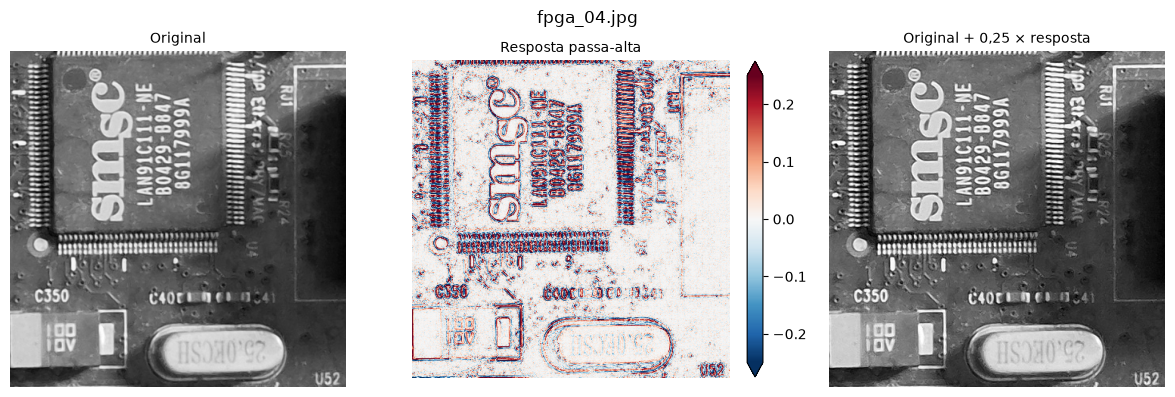

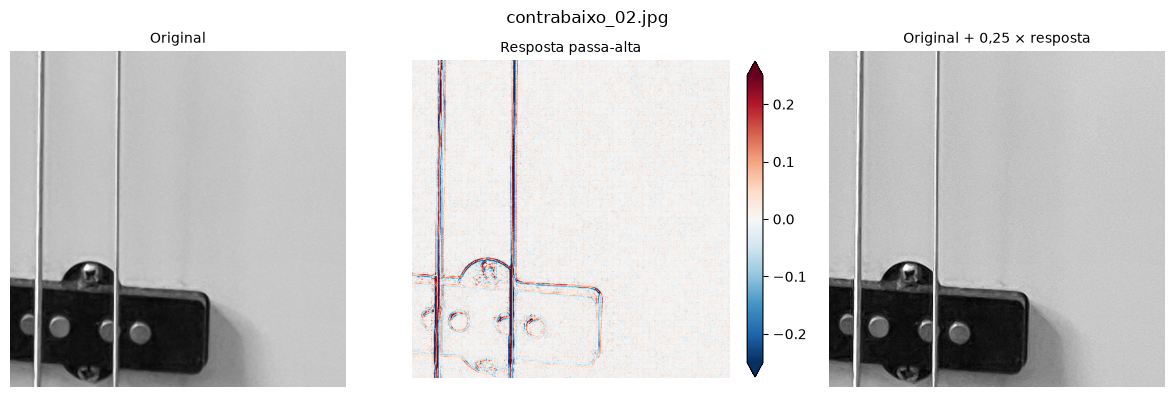

In [6]:
KERNEL_ALTA=np.array([[0,-1,0],[-1,4,-1],[0,-1,0]],dtype=np.float32)
ALFA=0.25
linhas=[]
for item in SELECAO:
    classe=item['classe']
    referencia=IMAGENS[classe]
    resposta=filtrar_frequencia(referencia,KERNEL_ALTA)
    realce=np.clip(referencia+ALFA*resposta,0,1)
    salvar_imagem(realce,DERIVADAS/'passa_alta'/classe/'realce.png')
    linhas.append({'classe':classe,'filtro':'passa-alta clássico','fator_realce':ALFA})

    fig,eixos=plt.subplots(1,3,figsize=(12,4))
    eixos[0].imshow(recortar(referencia,item['detalhe']),cmap='gray',vmin=0,vmax=1)
    mapa=eixos[1].imshow(recortar(resposta,item['detalhe']),cmap='RdBu_r',vmin=-0.25,vmax=0.25)
    eixos[2].imshow(recortar(realce,item['detalhe']),cmap='gray',vmin=0,vmax=1)
    eixos[0].set_title('Original')
    eixos[1].set_title('Resposta passa-alta')
    eixos[2].set_title('Original + 0,25 × resposta')
    fig.colorbar(mapa,ax=eixos[1],fraction=0.045,extend='both')
    for eixo in eixos:eixo.axis('off')
    fig.suptitle(item['arquivo'])
    finalizar_figura(fig,f'passa_alta_{classe}')

passa_alta=pd.DataFrame(linhas)

### Interpretação do passa-alta

Na FPGA, foram destacados contornos de componentes, inscrições e terminais. No contrabaixo,
foram destacadas cordas, captadores e transições do acabamento. As bordas ficaram mais
visíveis no realce, mas o filtro também responde a textura e variações que não interessam.

Entre os métodos utilizados nesta atividade, o **passa-alta clássico aplicado à imagem sem
ruído apresentou a melhor definição estrutural**, pois realçou contornos finos sem a
suavização do passa-baixa. Isso não significa que ele seja sempre melhor: aplicado a uma
imagem ruidosa, também realçaria o ruído.

Esse filtro pode ajudar na inspeção de componentes, extração de contornos e preparação
para segmentação. Ele não recupera detalhes ausentes e não identifica sozinho quais bordas
pertencem ao objeto de interesse.

## 5. Comparação final

In [7]:
resumo=[]
for item in SELECAO:
    classe=item['classe']
    resumo.extend([
        {'classe':classe,'etapa':'Imagem original','resultado':'Referência com os detalhes preservados.'},
        {'classe':classe,'etapa':'Ruído gaussiano','resultado':'Granulação distribuída; prejudica regiões e bordas de baixo contraste.'},
        {'classe':classe,'etapa':'Sal e pimenta','resultado':'Pontos extremos isolados; menor PSNR entre os ruídos testados.'},
        {'classe':classe,'etapa':'Passa-baixa gaussiano','resultado':'Reduz variações, mas também suaviza inscrições, terminais e cordas.'},
        {'classe':classe,'etapa':'Passa-alta','resultado':'Realça contornos e detalhes; também pode destacar textura e ruído.'}
    ])
resumo=pd.DataFrame(resumo)
resumo.to_csv(TABELAS/'sintese.csv',index=False)
for classe in ['fpga','contrabaixo']:
    display(Markdown(f'**{classe.upper()}**'))
    mostrar_tabela(resumo[resumo.classe==classe],{'etapa':'Etapa','resultado':'Resultado observado'})

**FPGA**

Etapa,Resultado observado
Imagem original,Referência com os detalhes preservados.
Ruído gaussiano,Granulação distribuída; prejudica regiões e bordas de baixo contraste.
Sal e pimenta,Pontos extremos isolados; menor PSNR entre os ruídos testados.
Passa-baixa gaussiano,"Reduz variações, mas também suaviza inscrições, terminais e cordas."
Passa-alta,Realça contornos e detalhes; também pode destacar textura e ruído.


**CONTRABAIXO**

Etapa,Resultado observado
Imagem original,Referência com os detalhes preservados.
Ruído gaussiano,Granulação distribuída; prejudica regiões e bordas de baixo contraste.
Sal e pimenta,Pontos extremos isolados; menor PSNR entre os ruídos testados.
Passa-baixa gaussiano,"Reduz variações, mas também suaviza inscrições, terminais e cordas."
Passa-alta,Realça contornos e detalhes; também pode destacar textura e ruído.


Com os parâmetros escolhidos, **sal e pimenta degradou mais as duas imagens segundo o
PSNR**. O filtro Gaussiano aumentou o PSNR e melhorou parcialmente a aparência, mas não
recuperou a referência e perdeu detalhes. Filtros antes do processamento podem ser úteis
em segmentação, detecção de bordas, reconhecimento de padrões e inspeção, desde que o
tipo de filtro corresponda ao ruído presente e preserve as estruturas necessárias.

## Conclusão

Os dois ruídos produziram efeitos diferentes. O gaussiano alterou quase todos os pixels
em menor intensidade, enquanto sal e pimenta modificou 5% das posições com valores extremos.
Nesta configuração, sal e pimenta teve o menor PSNR e a maior degradação numérica nas duas
classes.

Os filtros gaussianos reduziram as variações e aumentaram o PSNR, mas não reconstruíram
completamente as imagens. O kernel 3×3 preservou melhor os detalhes da FPGA; o 7×7 obteve
melhor equilíbrio no contrabaixo e maior PSNR para sal e pimenta, apesar de espalhar os
impulsos. Isso confirma que maior suavização não significa necessariamente melhor resultado.

O passa-alta destacou componentes e inscrições na FPGA, além de cordas e captadores no
contrabaixo. **Foi o operador com melhor definição estrutural no conjunto analisado**,
quando aplicado às imagens sem ruído, porque realçou os contornos sem suavizá-los. Porém,
ele também realçaria ruído e textura, por isso deve ser aplicado depois de avaliar a entrada.

Em uma aplicação real, a escolha depende do objetivo. Um filtro pode ajudar a estabilizar
segmentação e detecção de contornos, mas também pode apagar a informação necessária para
reconhecer ou inspecionar o objeto.

## Arquivos e referências

O notebook recria as tabelas em `tabelas/atividade_3` e as imagens derivadas em
`dataset/derivadas/atividade_3`. São necessárias apenas as duas fotografias originais e
as bibliotecas da preparação.

- Enunciado: *Filtragem de Imagens e Análise de Ruído*, Prof. Rafael Carmo.
- [OpenCV — Transformada de Fourier](https://docs.opencv.org/4.x/de/dbc/tutorial_py_fourier_transform.html).
- [OpenCV — suavização](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html).
- [OpenCV — gradientes](https://docs.opencv.org/4.x/d5/d0f/tutorial_py_gradients.html).